![Banner](../images/09_10_banner_rs_object_detection.png)


# Object Detection in Aerial Imagery

This notebook detects swimming pools in aerial-image tiles with an HSV and contour baseline, then uses GeoLattice for box geometry, non-maximum suppression, tiling, and a detector trained on annotated tree tiles.


## Overview

Image classification assigns one label to a whole image; semantic segmentation assigns a label to every pixel; **object detection** returns a set of object instances, each with a category, confidence score, and location. Here the objects are swimming pools in small aerial-image tiles. A detector can answer *where are the pools and how many are there?* rather than only *does this tile contain a pool?*

This notebook starts with the dataset's reproducible OpenCV HSV/contour detector, then connects that baseline to GeoLattice's box geometry, non-maximum suppression (NMS), large-image tiling, detector architectures, and evaluation/training interfaces. The classical detector is useful when pool water has a distinctive colour; it is not a learned CNN and will fail when shadows, roofs, water, or seasonal conditions look similar.

> **Important data limitation:** this folder contains image tiles and a prototype notebook, but no independent, verified pool bounding-box annotations. Consequently, we can inspect predictions and tune a heuristic, but we **cannot honestly train a supervised neural detector or report precision, recall, AP, or mAP** from this dataset alone. Predictions from the HSV detector are not ground truth for evaluating that same detector. The notebook shows the exact annotation and GeoLattice interfaces needed to continue once labels are added.


## Core concepts

### Learning objectives

1. Distinguish image classification, semantic segmentation, and instance detection.
2. Derive and implement an HSV-mask/contour pool proposal baseline.
3. Use bounding-box IoU, NMS, and overlapping image windows to handle duplicate proposals and small objects.
4. Explain Faster R-CNN, RetinaNet, FCOS, YOLO, and Mask R-CNN with their core equations.
5. Understand how to create a leakage-resistant annotated dataset and evaluate it with mAP.
6. Interpret filename-derived coordinates cautiously and export approximate detection footprints.
7. Train and evaluate a GeoLattice-built detector on the annotated tree-chip dataset.

### Contents

1. Environment and Dataset
2. HSV colour thresholding and contour proposals
3. Overlapping-window detection and duplicate suppression
4. Batch results and cautious filename-derived coordinates
5. Detection geometry and model architectures
6. Annotation, split design, training, and evaluation
7. Tree detection with annotated aerial-image tiles
8. Limitations and a practical workflow


## Environment and Dataset

The supplied tiles are RGB aerial photographs (usually 1920 x 939 pixels). We resolve the dataset folder from either the repository root or this notebook's folder. GPU availability is reported for later neural-detector experiments; the OpenCV baseline itself runs on CPU.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `pyyaml`, which no GeoLattice option installs: `pip install pyyaml`.

In [1]:
from pathlib import Path
import json
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch

CANDIDATES = [
    Path("../../../../Data/08_remote_sensing/08_10_object_detection/cv2-pool-detection-master"),
    Path("Data/08_remote_sensing/08_09_image_classification/cv2-pool-detection-master"),
]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError(
        "Run Jupyter from this notebook's folder or from the GeoLattice repository root."
    )

IMAGE_DIR = DATA / "data"
IMAGE_PATHS = sorted(IMAGE_DIR.glob("*.jpg"))
if not IMAGE_PATHS:
    raise FileNotFoundError(f"No .jpg tiles found in {IMAGE_DIR}")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dataset: {DATA.resolve()}")
print(f"JPEG tiles: {len(IMAGE_PATHS)} | detector-training device if needed: {DEVICE}")
print(f"OpenCV {cv2.__version__} | PyTorch {torch.__version__}")

Dataset: /home/zia207/Github/GeoLattice/Data/08_remote_sensing/08_10_object_detection/cv2-pool-detection-master
JPEG tiles: 29 | detector-training device if needed: cuda
OpenCV 5.0.0 | PyTorch 2.14.0+cu132


(height, width)
(939, 1920)    29
Name: tiles, dtype: int64

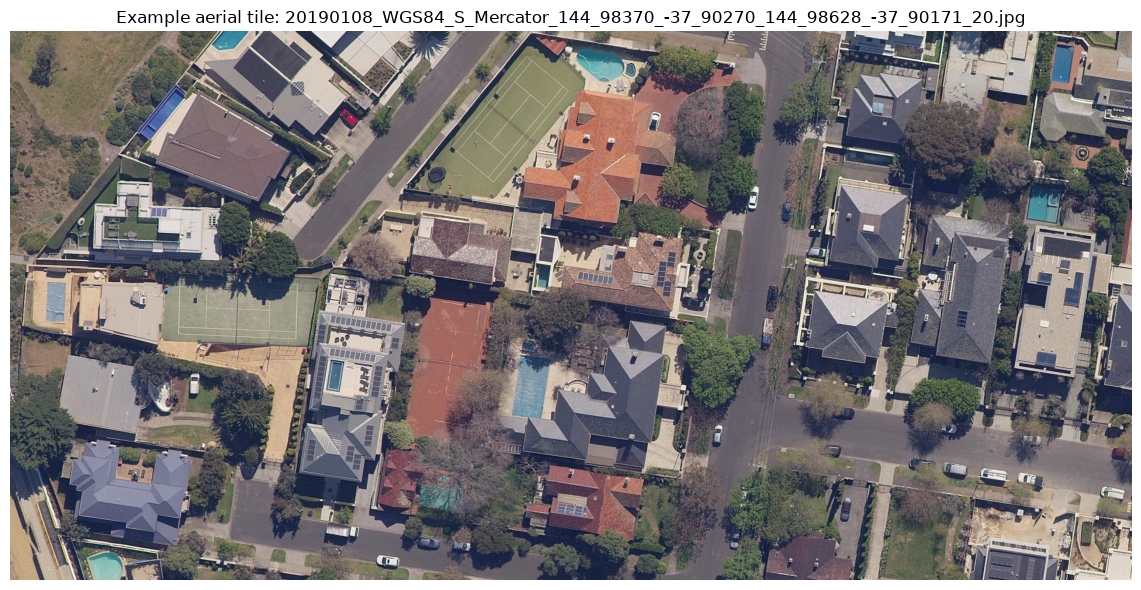

In [2]:
def read_rgb(path):
    # Read as RGB; fail explicitly if OpenCV cannot decode the tile.
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise OSError(f"Could not read image: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

image_shapes = []
for path in IMAGE_PATHS:
    image_shapes.append(read_rgb(path).shape[:2])
display(pd.Series(image_shapes, name="(height, width)").value_counts().rename("tiles"))

sample_path = IMAGE_PATHS[min(4, len(IMAGE_PATHS) - 1)]
sample_rgb = read_rgb(sample_path)
fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(sample_rgb)
ax.set_title(f"Example aerial tile: {sample_path.name}")
ax.axis("off")
plt.tight_layout()
plt.show()

## HSV colour thresholding and contour proposals

RGB values mix colour and brightness. HSV separates hue $H$, saturation $S$, and value $V$; OpenCV encodes hue on $[0,179]$ and saturation/value on $[0,255]$. A simple pool-water mask is

$$
M(x,y)=\mathbf{1}\{H_{\min}\le H(x,y)\le H_{\max},\;
S(x,y)\ge S_{\min},\;V(x,y)\ge V_{\min}\}.
$$

The starting bounds below are those used in the original sample detector. They are **heuristic operating parameters**, not fitted model weights. Morphological opening removes isolated specks, and closing fills small gaps:

$$
M\circ B=(M\ominus B)\oplus B,\qquad
M\bullet B=(M\oplus B)\ominus B,
$$

where $\ominus$ and $\oplus$ denote erosion and dilation by structuring element $B$. Connected external contours then provide candidate regions. A contour's axis-aligned box is $(x_0,y_0,x_1,y_1)$, and the contour fill ratio $A_c/A_b$ can serve as a rough ranking score, not a calibrated probability.


In [3]:
# OpenCV HSV ranges use H in [0, 179], S/V in [0, 255].
HSV_LOWER = np.array([50, 40, 140], dtype=np.uint8)
HSV_UPPER = np.array([120, 255, 255], dtype=np.uint8)
OPEN_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
CLOSE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

MIN_CONTOUR_AREA = 80
MIN_BOX_AREA = 250
MAX_BOX_AREA = 25_000

def hsv_pool_proposals(rgb, *, min_contour_area=MIN_CONTOUR_AREA,
                       min_box_area=MIN_BOX_AREA, max_box_area=MAX_BOX_AREA):
    # Return heuristic pool boxes (xyxy pixels), fill-ratio scores, and mask.
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, HSV_LOWER, HSV_UPPER)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, OPEN_KERNEL)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, CLOSE_KERNEL)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes, scores = [], []
    for contour in contours:
        contour_area = cv2.contourArea(contour)
        if contour_area < min_contour_area:
            continue
        x, y, width, height = cv2.boundingRect(contour)
        box_area = width * height
        if not min_box_area <= box_area <= max_box_area:
            continue
        boxes.append([x, y, x + width, y + height])
        scores.append(contour_area / box_area)
    if not boxes:
        return np.empty((0, 4), dtype=float), np.empty(0, dtype=float), mask
    return np.asarray(boxes, dtype=float), np.asarray(scores, dtype=float), mask

sample_boxes, sample_scores, sample_mask = hsv_pool_proposals(sample_rgb)
print(f"{sample_path.name}: {len(sample_boxes)} heuristic proposals")

20190108_WGS84_S_Mercator_144_98370_-37_90270_144_98628_-37_90171_20.jpg: 9 heuristic proposals


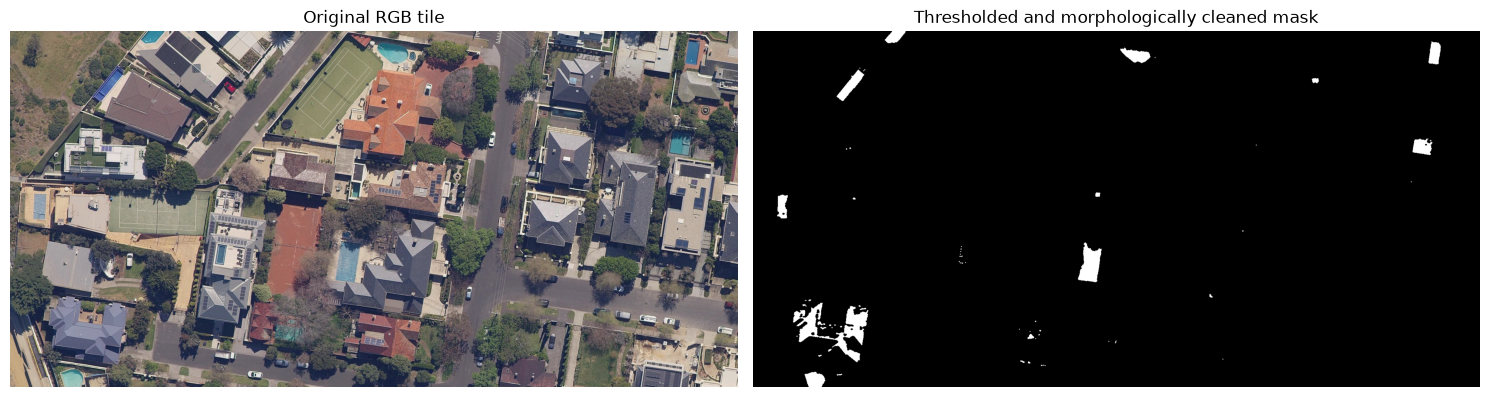

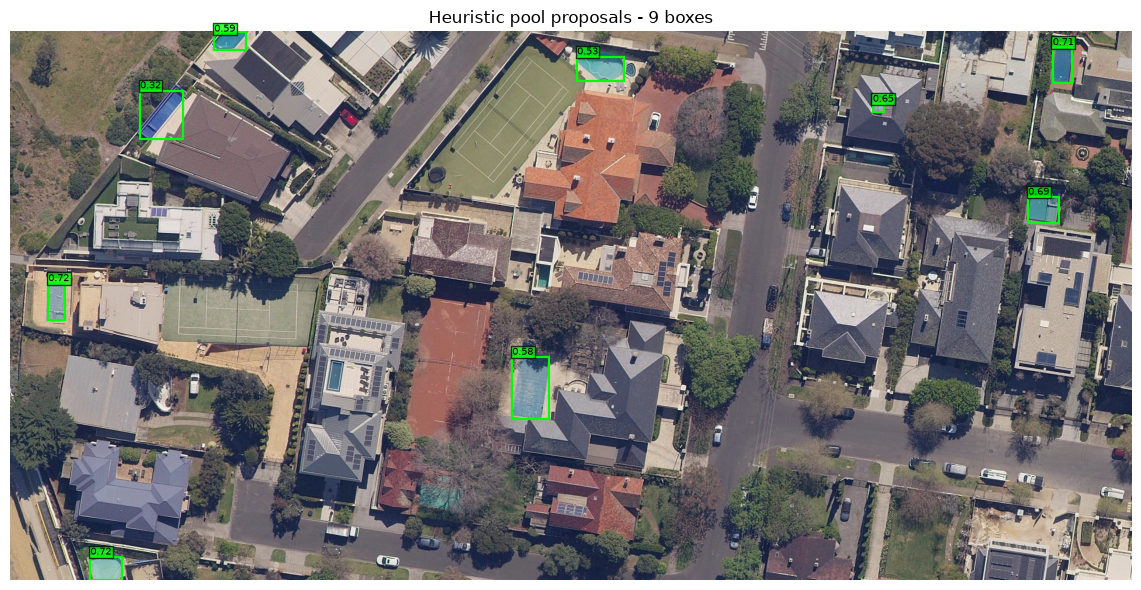

In [4]:
def show_detections(rgb, boxes, scores=None, *, title="Heuristic pool proposals"):
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.imshow(rgb)
    for i, (x0, y0, x1, y1) in enumerate(boxes):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                               fill=False, edgecolor="lime", linewidth=1.6))
        if scores is not None:
            ax.text(x0, max(0, y0 - 4), f"{scores[i]:.2f}", color="black",
                    fontsize=7, bbox={"facecolor": "lime", "alpha": 0.75, "pad": 1})
    ax.set_title(f"{title} - {len(boxes)} boxes")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].imshow(sample_rgb)
axes[0].set_title("Original RGB tile")
axes[1].imshow(sample_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Thresholded and morphologically cleaned mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
show_detections(sample_rgb, sample_boxes, sample_scores)


### Parameter sensitivity: thresholds are not universal

Raising the minimum contour or box area suppresses speckle but can miss small pools; lowering it increases false positives. A hue/saturation/value threshold that works on one image may fail under haze, shadows, roofs, or a different sensor. The small table below is a **proposal-count sensitivity check only**. Since independent box labels are absent, it does not identify which setting is most accurate.


In [5]:
parameter_rows = []
for min_area in (40, 80, 160, 320):
    boxes, scores, _ = hsv_pool_proposals(sample_rgb, min_contour_area=min_area)
    parameter_rows.append({"minimum contour area (px²)": min_area,
                           "proposal count": len(boxes),
                           "median fill ratio": float(np.median(scores)) if len(scores) else np.nan})
display(pd.DataFrame(parameter_rows))

,minimum contour area (px²),proposal count,median fill ratio
0,40,9,0.654135
1,80,9,0.654135
2,160,9,0.654135
3,320,8,0.641075


## Overlapping-window detection and duplicate suppression

Small objects can disappear when a large image is resized to a network's fixed input size. A sliding-window detector instead runs on overlapping crops, translates local boxes back to the full-image coordinate system, and suppresses duplicate boxes near crop edges. GeoLattice's `detection_tiles` generates windows; `box_iou` and `nms` implement the standard box overlap and greedy suppression.

For boxes $A$ and $B$,

$$
\operatorname{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$

Greedy NMS sorts boxes by score, keeps the highest-scoring box, and removes lower-scoring boxes whose IoU exceeds threshold $\tau$. The threshold trades duplicate suppression against accidentally merging adjacent pools.


8 windows -> 10 boxes after NMS


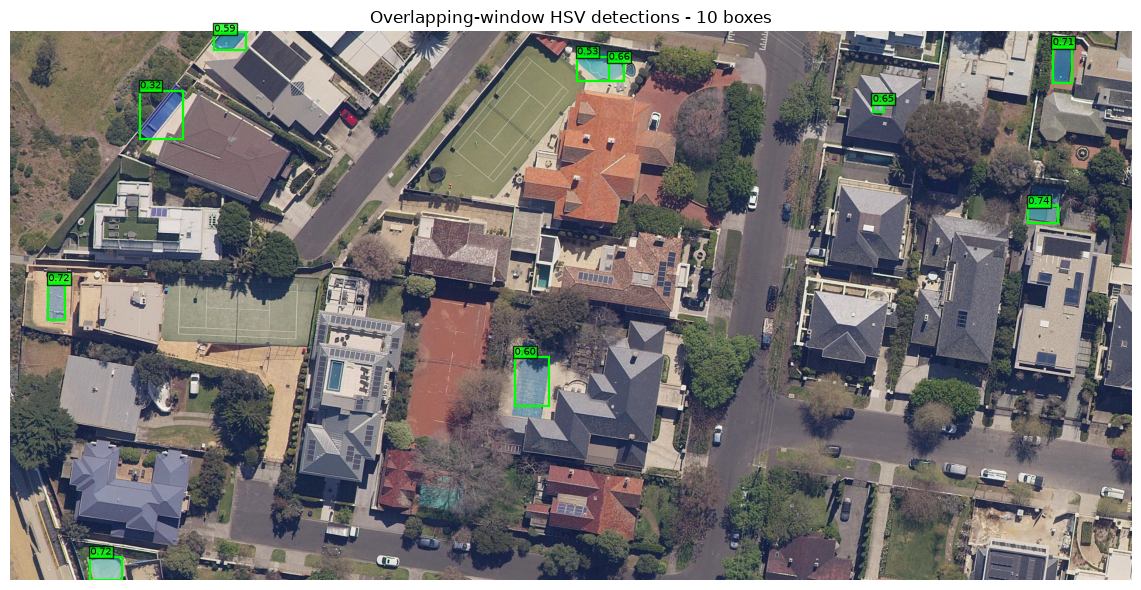

In [6]:
from geolattice.rsense.classify import image_classification as ic

def detect_tiled_hsv(rgb, *, tile=640, overlap=0.20, nms_iou=0.35):
    # Detect in overlapping windows; return full-image xyxy boxes and heuristic scores.
    height, width = rgb.shape[:2]
    windows = ic.detection_tiles(height, width, tile=tile, overlap=overlap)
    all_boxes, all_scores = [], []
    for row, col, window_size in windows:
        crop = rgb[row:min(row + window_size, height),
                    col:min(col + window_size, width)]
        boxes, scores, _ = hsv_pool_proposals(crop)
        if len(boxes):
            boxes[:, [0, 2]] += col
            boxes[:, [1, 3]] += row
            all_boxes.extend(boxes.tolist())
            all_scores.extend(scores.tolist())
    if not all_boxes:
        return np.empty((0, 4), dtype=float), np.empty(0, dtype=float), windows
    boxes = np.asarray(all_boxes, dtype=float)
    scores = np.asarray(all_scores, dtype=float)
    keep = ic.nms(boxes, scores, iou_threshold=nms_iou)
    return boxes[keep], scores[keep], windows

tiled_boxes, tiled_scores, windows = detect_tiled_hsv(sample_rgb)
print(f"{len(windows)} windows -> {len(tiled_boxes)} boxes after NMS")
show_detections(sample_rgb, tiled_boxes, tiled_scores, title="Overlapping-window HSV detections")

In [7]:
# Verify the geometry and NMS helpers on a tiny controlled example.
box_a = np.array([[0, 0, 10, 10], [1, 1, 11, 11], [20, 20, 30, 30]], dtype=float)
scores_a = np.array([0.9, 0.7, 0.8])
print("IoU(box 1, box 2):", round(float(ic.box_iou(box_a[:1], box_a[1:2])[0, 0]), 3))
print("Kept indices:", ic.nms(box_a, scores_a, iou_threshold=0.5).tolist())

IoU(box 1, box 2): 0.681
Kept indices: [0, 2]


## Batch results and cautious filename-derived coordinates

We run the same baseline on every JPEG and summarize proposal counts. Names in this sample appear to encode lower-left and upper-right longitude/latitude pairs. The parser below decodes that naming convention and maps pixel boxes to approximate WGS84 polygons by linear interpolation. This is useful for illustration, **not a substitute for checking the imagery's authoritative CRS, image orientation, and georeferencing metadata**.

If adjacent images overlap, the same pool may be detected twice. Geographic polygon NMS can merge such duplicate footprints. Counts summed before that step are therefore not necessarily counts of unique real-world pools.


In [8]:
def parse_encoded_coordinate(degrees, fraction):
    sign = -1 if degrees.startswith("-") else 1
    return sign * (abs(int(degrees)) + int(fraction) / (10 ** len(fraction)))

COORDINATE_PATTERN = re.compile(
    r"_(\d{3})_(\d{5})_(-?\d{2})_(\d{5})_"
    r"(\d{3})_(\d{5})_(-?\d{2})_(\d{5})_\d+\.jpg$"
)

def tile_bounds_from_name(path):
    match = COORDINATE_PATTERN.search(Path(path).name)
    if match is None:
        return None
    left = parse_encoded_coordinate(match.group(1), match.group(2))
    lat_a = parse_encoded_coordinate(match.group(3), match.group(4))
    right = parse_encoded_coordinate(match.group(5), match.group(6))
    lat_b = parse_encoded_coordinate(match.group(7), match.group(8))
    return min(left, right), min(lat_a, lat_b), max(left, right), max(lat_a, lat_b)

print("Example encoded bounds (min lon, min lat, max lon, max lat):")
print(sample_path.name, "->", tile_bounds_from_name(sample_path))

Example encoded bounds (min lon, min lat, max lon, max lat):
20190108_WGS84_S_Mercator_144_98370_-37_90270_144_98628_-37_90171_20.jpg -> (144.9837, -37.9027, 144.98628, -37.90171)


In [9]:
all_detections = []
image_summary = []
for path in IMAGE_PATHS:
    rgb = read_rgb(path)
    boxes, scores, _ = hsv_pool_proposals(rgb)
    bounds = tile_bounds_from_name(path)
    image_summary.append({"image": path.name, "height": rgb.shape[0],
                          "width": rgb.shape[1], "proposal_count": len(boxes),
                          "has_filename_bounds": bounds is not None})
    if bounds is None:
        continue
    min_lon, min_lat, max_lon, max_lat = bounds
    height, width = rgb.shape[:2]
    for box, score in zip(boxes, scores):
        x0, y0, x1, y1 = box
        lon0 = min_lon + (x0 / width) * (max_lon - min_lon)
        lon1 = min_lon + (x1 / width) * (max_lon - min_lon)
        lat1 = max_lat - (y0 / height) * (max_lat - min_lat)
        lat0 = max_lat - (y1 / height) * (max_lat - min_lat)
        all_detections.append({"image": path.name, "score": float(score),
                               "label": "pool", "x0": x0, "y0": y0, "x1": x1, "y1": y1,
                               "min_lon": lon0, "min_lat": lat0,
                               "max_lon": lon1, "max_lat": lat1})

summary = pd.DataFrame(image_summary)
display(summary.describe(include="all"))
print("Images with parseable filename bounds:",
      f"{summary['has_filename_bounds'].sum()} / {len(summary)}")
print("Raw HSV proposals across images:", len(all_detections))

,image,height,width,proposal_count,has_filename_bounds
count,29,29.0,29.0,29.000000,29
unique,29,NaN,NaN,NaN,1
top,20190108_WGS84_S_Mercator_144_98370_-37_89898_...,NaN,NaN,NaN,True
freq,1,NaN,NaN,NaN,29
mean,NaN,939.0,1920.0,6.620690,NaN
std,NaN,0.0,0.0,3.539711,NaN
min,NaN,939.0,1920.0,0.000000,NaN
25%,NaN,939.0,1920.0,5.000000,NaN
50%,NaN,939.0,1920.0,7.000000,NaN
75%,NaN,939.0,1920.0,9.000000,NaN


Images with parseable filename bounds: 29 / 29
Raw HSV proposals across images: 192


In [10]:
import geopandas as gpd
from shapely.geometry import box as shapely_box

if all_detections:
    detections_gdf = gpd.GeoDataFrame(
        all_detections,
        geometry=[shapely_box(d["min_lon"], d["min_lat"], d["max_lon"], d["max_lat"])
                  for d in all_detections],
        crs="EPSG:4326",
    )
    merged_gdf = ic.merge_detections(
        detections_gdf, iou_threshold=0.5, by="label", score_col="score"
    )
    print(f"Raw proposals: {len(detections_gdf)} | after geographic duplicate merging: {len(merged_gdf)}")
    display(merged_gdf[["image", "score", "label", "geometry"]].head())
else:
    detections_gdf = gpd.GeoDataFrame(
        columns=["image", "score", "label", "geometry"], geometry="geometry", crs="EPSG:4326"
    )
    merged_gdf = detections_gdf.copy()
    print("No proposals with parseable coordinate bounds were produced.")

Raw proposals: 192 | after geographic duplicate merging: 189


,image,score,label,geometry
0,20190108_WGS84_S_Mercator_144_98617_-37_89526_...,0.804911,pool,"POLYGON ((144.98872 -37.89463, 144.98872 -37.8..."
1,20190108_WGS84_S_Mercator_144_98370_-37_90177_...,0.782654,pool,"POLYGON ((144.98614 -37.90177, 144.98614 -37.9..."
2,20190108_WGS84_S_Mercator_144_98617_-37_89991_...,0.761240,pool,"POLYGON ((144.98719 -37.89973, 144.98719 -37.8..."
3,20190108_WGS84_S_Mercator_144_98617_-37_90828_...,0.760190,pool,"POLYGON ((144.98636 -37.90822, 144.98636 -37.9..."
4,20190108_WGS84_S_Mercator_144_98617_-37_90084_...,0.759976,pool,"POLYGON ((144.98807 -37.90048, 144.98807 -37.9..."


## Detection geometry and model architectures


### From boxes to a detection loss

A detector predicts a set of class scores and box coordinates. For a matched object with class $c$ and ground-truth box $b^*$, a common objective is

$$
\mathcal{L}=\lambda_{\mathrm{cls}}\mathcal{L}_{\mathrm{cls}}(p,c)
+\lambda_{\mathrm{box}}\mathcal{L}_{\mathrm{box}}(b,b^*),
\qquad
\mathcal{L}_{\mathrm{box}}=\sum_{q\in\{x,y,w,h\}}\operatorname{SmoothL1}(b_q-b_q^*).
$$

The model must also decide which candidate locations correspond to objects (assignment/matching), and how to handle the many more background locations than pools.


### Faster R-CNN: proposals, then refinement

Faster R-CNN is a two-stage detector. A backbone and feature pyramid produce feature maps $F$. A region proposal network (RPN) predicts objectness $p_i$ and anchor offsets $t_i$:

$$
\mathcal{L}_{\mathrm{RPN}}=\frac{1}{N_{\mathrm{cls}}}\sum_i
\operatorname{BCE}(p_i,p_i^*)+
\lambda\frac{1}{N_{\mathrm{reg}}}\sum_i p_i^*\operatorname{SmoothL1}(t_i-t_i^*).
$$

Proposals are cropped/pooled to a common feature size; a second head predicts the pool/background class and refined box. Region proposals focus computation on likely objects, but add proposal/matching stages and can be slower than one-stage methods.


### RetinaNet: dense anchors and focal loss

RetinaNet predicts class probabilities and box offsets at every location and anchor on a feature pyramid. Its focal loss reduces the contribution of easy background examples:

$$
\operatorname{FL}(p_t)=-\alpha_t(1-p_t)^\gamma\log(p_t).
$$

When $p_t\to1$, the factor $(1-p_t)^\gamma$ suppresses easy examples; hard positives and confusing negatives retain more weight. This addresses the extreme foreground/background imbalance of dense prediction.


### FCOS: anchor-free points

FCOS assigns positive feature-map locations inside a ground-truth box. At a positive location $(x,y)$ it regresses distances to the four sides:

$$
(l,t,r,b)=(x-x_0,\;y-y_0,\;x_1-x,\;y_1-y),
\qquad
\mathcal{L}=\mathcal{L}_{\mathrm{focal}}+\lambda\mathcal{L}_{\mathrm{GIoU}}.
$$

An optional centerness score downweights low-quality predictions far from the box centre. Removing anchors reduces anchor-scale and aspect-ratio design choices, but point assignment and NMS are still needed.


### YOLO: one-stage grid predictions

YOLO-style models predict objectness, box geometry, and class scores in one forward pass over one or more feature scales. For a grid point with centre $(c_x,c_y)$ and stride $s$, a typical parameterization is

$$
x=c_x+s\,\sigma(t_x),\quad y=c_y+s\,\sigma(t_y),\quad
w=s\,e^{t_w},\quad h=s\,e^{t_h}.
$$

Modern YOLO variants differ in assignment, box loss, and whether heads are anchor-based; the common idea is joint dense prediction followed by confidence filtering and NMS. Ultralytics YOLO weights may require an extra package and a separate annotation/training setup.


### Mask R-CNN: boxes plus instance masks

Mask R-CNN adds an FCN mask head to each positive region of Faster R-CNN. For each RoI it predicts a class-specific mask $M$ with pixelwise binary cross-entropy:

$$
\mathcal{L}_{\mathrm{total}}=
\mathcal{L}_{\mathrm{RPN}}+\mathcal{L}_{\mathrm{class}}+
\mathcal{L}_{\mathrm{box}}+\mathcal{L}_{\mathrm{mask}}.
$$

Use it when the pool's outline is required, not just its bounding rectangle. The current dataset has no polygon masks either.


### Which detector is a sensible starting point?

| Model | Family | Strength | Trade-off |
|---|---|---|---|
| Faster R-CNN | Two-stage, region proposals | Strong general-purpose baseline; explicit proposal refinement | More latency and proposal machinery |
| RetinaNet | One-stage, anchor-based | Focal loss handles dense foreground/background imbalance | Anchor configuration and matching matter |
| FCOS | One-stage, anchor-free | Simple point-based box regression | Still needs scale assignment and NMS |
| YOLO | One-stage, dense | Fast inference and mature deployment ecosystem | Version/weight conventions and training APIs vary |
| Mask R-CNN | Two-stage, boxes + masks | Instance outline as well as a box | More annotation effort and compute |

GeoLattice exposes torchvision Faster R-CNN, RetinaNet, FCOS, and Mask R-CNN through `build_object_detector`; its YOLO path delegates to Ultralytics. On this small-object aerial dataset, crop/window size and verified labels are at least as important as architecture choice.


## Annotation, split design, training, and evaluation


### Why the current images cannot support a valid accuracy score

Supervised object detection requires, for every image, a set of **verified** boxes and class IDs. A box missed by annotation is counted as a false positive; an omitted pool is counted as a false negative. There are no independent box labels in the supplied folder, so generating labels from the HSV detector and scoring that detector against them would be circular.

Annotate a representative selection of tiles with a tool that exports COCO or another explicit box format. Review difficult cases and include empty-background images. Split by **geographic tile/site**, not by random boxes or crops: neighboring crops share roofs, lighting, and sometimes the same pool, so a random crop split overstates generalization. Keep a final site-level test set untouched until model selection is complete.


### PyTorch target format and GeoLattice hooks

Torchvision-style training batches are `(images, targets)`, where each target has `boxes` in pixel `xyxy` coordinates and integer `labels` (`0` is reserved for background; in a two-class model, pool is `1`). For each image $i$:

$$
\texttt{boxes}_i\in\mathbb{R}^{N_i\times4},\quad
\texttt{labels}_i\in\{1,\ldots,C-1\}^{N_i}.
$$

GeoLattice's `train_detection` expects a list of image tensors and a list of target dictionaries. The loader needs a custom `collate_fn` because each image has a different number $N_i$ of boxes. This code shows the target and collate shapes; it deliberately does not fabricate labels or start training.


In [11]:
def detection_collate(batch):
    # Keep variable-size image and box lists instead of stacking targets.
    images, targets = zip(*batch)
    return list(images), list(targets)

# Example target for a manually annotated tile. Replace these coordinates with reviewed labels.
example_target = {
    "boxes": torch.tensor([[120.0, 210.0, 184.0, 278.0]], dtype=torch.float32),
    "labels": torch.tensor([1], dtype=torch.int64),  # 1 = pool; 0 is background
}
print("boxes:", tuple(example_target["boxes"].shape),
      "| labels:", tuple(example_target["labels"].shape),
      "| device available:", DEVICE)

boxes: (1, 4) | labels: (1,) | device available: cuda


### GeoLattice object-detection API: available and used here

GeoLattice already provides object-detection functions in `geolattice.rsense.classify.image_classification`; a separate `object_detection.py` module is not needed. This notebook uses `detection_tiles`, `nms`, and `merge_detections` in the runnable HSV baseline. For a trained neural detector, the same module provides `build_object_detector` and georeferenced tiled inference through `detect_objects`; it also includes `box_iou`, `mean_average_precision`, and `count_objects`.

The HSV proposals below are **not** predictions from a GeoLattice neural detector. The pool tiles have no verified boxes, so fitting a pool-specific detector is not possible yet. Once independently labeled examples exist, train a torchvision detector and pass the trained model plus a georeferenced `xarray` raster to GeoLattice `detect_objects`. That function handles overlapping windows, global class-wise NMS, and conversion of predicted boxes to map-coordinate polygons.

The code cell smoke-tests the GeoLattice metric API on one deliberately perfect synthetic box. Its score verifies interface behavior only; it is **not** a score on the pool images.


In [12]:
# Confirm the installed GeoLattice detector API without downloading pretrained weights.
import inspect

required_detection_api = [
    "build_object_detector", "box_iou", "nms", "mean_average_precision",
    "detection_tiles", "merge_detections", "detect_objects", "count_objects",
]
missing_api = [name for name in required_detection_api if not callable(getattr(ic, name, None))]
if missing_api:
    raise ImportError(f"This GeoLattice installation is missing detection APIs: {missing_api}")
print("GeoLattice object-detection APIs available:", ", ".join(required_detection_api))
print("Builder:", inspect.signature(ic.build_object_detector))
print("Georeferenced inference:", inspect.signature(ic.detect_objects))

# Toy interface check only: one exact prediction matches one synthetic reference box.
toy_ground_truth = [{"boxes": np.array([[10, 10, 30, 30]]), "labels": np.array([1])}]
toy_predictions = [{"boxes": np.array([[10, 10, 30, 30]]),
                    "scores": np.array([0.99]), "labels": np.array([1])}]
toy_metric = ic.mean_average_precision(toy_predictions, toy_ground_truth, iou_thresholds=(0.5,))
print(f"Synthetic one-box mAP@0.50 smoke test: {toy_metric['map@0.50']:.1f} (not a dataset result)")


GeoLattice object-detection APIs available: build_object_detector, box_iou, nms, mean_average_precision, detection_tiles, merge_detections, detect_objects, count_objects
Builder: (arch: 'str' = 'faster_rcnn', *, num_classes: 'int' = 2, in_channels: 'int' = 3, pretrained: 'bool' = True, **kwargs: 'Any')
Georeferenced inference: (model, image: 'xr.DataArray | xr.Dataset', *, tile: 'int' = 640, overlap: 'int' = 128, score_threshold: 'float' = 0.3, iou_threshold: 'float' = 0.5, class_names: 'Mapping[int, str] | None' = None, normalizer: 'Normalizer | None' = None, device: 'str | None' = None)
Synthetic one-box mAP@0.50 smoke test: 1.0 (not a dataset result)


### Constructing a GeoLattice detector after labels exist

The following is a training template, not an executed model result. Once a `Dataset` reads *manually reviewed* annotations and returns RGB float tensors in $[0,1]$ plus the target format above, instantiate a GeoLattice detector and pass train/validation loaders. Start with one architecture, keep validation tiles separate by site, and select thresholds/checkpoints on validation only. After training, use `ic.detect_objects(model, image_da, ...)` on a georeferenced `xarray.DataArray`/`Dataset` to obtain map-coordinate boxes.

```python
from geolattice.rsense.classify.image_classification import build_object_detector
from geolattice.rsense.dl.train import train_detection

model = build_object_detector(
    "faster_rcnn", num_classes=2, pretrained=True
)
history = train_detection(
    model, train_loader, val_loader,
    epochs=20, lr=1e-4, device=DEVICE, precision="16" if DEVICE == "cuda" else "32",
)

# image_da must be a georeferenced xarray raster in the model's expected band order.
boxes_gdf = ic.detect_objects(
    model, image_da, tile=640, overlap=128, score_threshold=0.3,
    class_names={1: "pool"}, device=DEVICE,
)
```

`pretrained=True` initializes the backbone from torchvision weights; it does not provide pool-specific training. `num_classes=2` counts background plus pool. The sample data cannot populate `train_loader`, so do not run this until independently verified annotations and a dataset class are in place.

### Detection metrics: AP and mAP

At IoU threshold $\tau$, a predicted box is a true positive only when it matches an as-yet-unmatched ground-truth box of the same class with $\operatorname{IoU}\ge\tau$. Precision and recall along the confidence-ranked list form a curve; average precision integrates its precision envelope. Mean AP averages AP over classes (and, for COCO-style mAP, over thresholds such as $0.50,0.55,\ldots,0.95$):

$$
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
\mathrm{mAP}_{.50:.95}=\frac{1}{10}\sum_{\tau\in\{.50,\ldots,.95\}}
\frac{1}{C}\sum_{c=1}^{C}\mathrm{AP}_{c,\tau}.
$$

GeoLattice `mean_average_precision` accepts per-image prediction dictionaries (`boxes`, `scores`, `labels`) and ground-truth dictionaries (`boxes`, `labels`). It becomes meaningful only when those ground-truth boxes were labeled independently of the evaluated predictions. Use site-level bootstrap or repeated site holdouts to express uncertainty when the number of independent locations is small.


## Tree detection with annotated aerial-image tiles

Unlike the pool tiles above, `Data/08_remote_sensing/08_10_object_detection/Tree_Detection` includes bounding-box annotations in YOLO format. We can train a supervised detector and evaluate it on the dataset's held-out test split. The dataset contains 91 RGB images resized/stretched to 640 x 640, one class (`tree`), and preassigned train/validation/test folders (64/18/9 images). These are image chips with no geotransform, so detections remain in image-pixel coordinates and cannot be exported as map coordinates without external georeferencing.

GeoLattice already integrates Ultralytics YOLO through `ic.build_object_detector("yolo", weights=...)`. We use its builder to initialize a pretrained YOLOv8 nano model, fine-tune on the supplied labels, and evaluate once on the test split. This is a small demonstration dataset: results are specific to its acquisition and split, and should not be treated as broad geographic validation. Roboflow metadata lists the source as CC BY 4.0; retain attribution to the [Tree Counting dataset](https://universe.roboflow.com/project-s402o/tree-counting-qiw3h) if redistributing the data or derived work.

For an image of width $W$ and height $H$, YOLO stores each box as normalized center and size $(c_x,c_y,w,h)\in[0,1]^4$. Convert to pixel corners by

$$x_0=W(c_x-w/2),\quad y_0=H(c_y-h/2),\quad x_1=W(c_x+w/2),\quad y_1=H(c_y+h/2).$$

The detector jointly predicts class/objectness and box offsets; during evaluation a predicted box is a true positive only when it matches an unmatched reference tree with sufficient IoU. The precision-recall curve yields AP, and AP@0.50 is reported for the single class.


In [13]:
from pathlib import Path
from PIL import Image
import yaml

TREE_CANDIDATES = [
    Path("../../../../Data/08_remote_sensing/08_10_object_detection/Tree_Detection"),
    Path("Data/08_remote_sensing/08_09_image_classification/Tree_Detection"),
]
TREE_DATA = next((p for p in TREE_CANDIDATES if p.is_dir()), None)
if TREE_DATA is None:
    raise FileNotFoundError("Could not find ../../../../Data/08_remote_sensing/08_10_object_detection/Tree_Detection from this working directory.")

TREE_SPLITS = {split: TREE_DATA / split for split in ("train", "valid", "test")}
for split, split_dir in TREE_SPLITS.items():
    if not (split_dir / "images").is_dir() or not (split_dir / "labels").is_dir():
        raise FileNotFoundError(f"Expected images/ and labels/ under {split_dir}")

tree_rows = []
for split, split_dir in TREE_SPLITS.items():
    images = sorted(p for p in (split_dir / "images").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    if not images:
        raise FileNotFoundError(f"No tree images found in {split_dir / 'images'}")
    box_total = 0
    class_ids = set()
    for image_path in images:
        label_path = split_dir / "labels" / f"{image_path.stem}.txt"
        if not label_path.is_file():
            raise FileNotFoundError(f"Missing YOLO annotation for {image_path.name}: {label_path}")
        for line_number, line in enumerate(label_path.read_text().splitlines(), start=1):
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"Invalid YOLO label {label_path}:{line_number}; expected class cx cy w h")
            class_id = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
                raise ValueError(f"Out-of-range normalized box in {label_path}:{line_number}")
            class_ids.add(class_id)
            box_total += 1
    tree_rows.append({"split": split, "images": len(images), "tree boxes": box_total,
                      "class IDs": sorted(class_ids)})

display(pd.DataFrame(tree_rows).set_index("split"))
if {row["split"]: row["class IDs"] for row in tree_rows} != {
    "train": [0], "valid": [0], "test": [0]
}:
    raise ValueError("Expected the single YOLO class ID 0 (tree) in all data splits.")


,images,tree boxes,class IDs
split,,,
train,64,5243,[0]
valid,18,1524,[0]
test,9,759,[0]


### Inspect the ground-truth boxes

The display below converts normalized YOLO coordinates back to pixel corners. Reviewing the annotations before training helps catch class/coordinate mistakes and reveals how dense the tree crowns are within each chip.


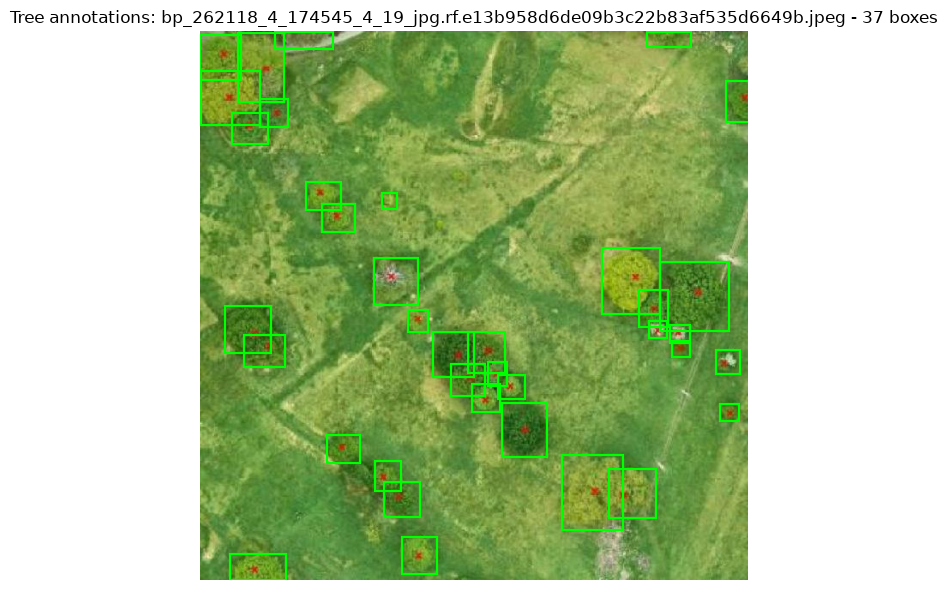

Ground-truth trees in example tile: 37


In [14]:
tree_sample_path = sorted((TREE_SPLITS["train"] / "images").glob("*"))[0]
tree_sample = np.asarray(Image.open(tree_sample_path).convert("RGB"))
tree_label_path = TREE_SPLITS["train"] / "labels" / f"{tree_sample_path.stem}.txt"
tree_sample_boxes = []
for line in tree_label_path.read_text().splitlines():
    class_id, cx, cy, bw, bh = line.split()
    cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
    h, w = tree_sample.shape[:2]
    tree_sample_boxes.append([w * (cx - bw / 2), h * (cy - bh / 2),
                              w * (cx + bw / 2), h * (cy + bh / 2)])
tree_sample_boxes = np.asarray(tree_sample_boxes, dtype=float).reshape(-1, 4)
show_detections(tree_sample, tree_sample_boxes, title=f"Tree annotations: {tree_sample_path.name}")
print(f"Ground-truth trees in example tile: {len(tree_sample_boxes)}")


### Train with the GeoLattice YOLO wrapper and test on held-out images

`ic.build_object_detector` returns the Ultralytics model for `arch="yolo"`; training is delegated to its supported `.train` method. The dataset YAML is written to a temporary file with explicit absolute paths, avoiding assumptions about how Ultralytics resolves the supplied Roboflow YAML's relative paths. Training uses the provided train/validation splits; the test split is reserved for the final evaluation cell below. Set `TREE_TRAIN_EPOCHS` higher for a more complete run. The default is kept modest for a tutorial notebook.


In [15]:
import tempfile

TREE_TRAIN_EPOCHS = 10
TREE_BATCH_SIZE = 8
TREE_DEVICE = 0 if torch.cuda.is_available() else "cpu"
TREE_RUNS_DIR = Path("runs/object_detection")
TREE_RUNS_DIR.mkdir(parents=True, exist_ok=True)

# Minimal Ultralytics dataset config with resolved, portable paths for the current machine.
tree_data_config = {
    "path": str(TREE_DATA.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {0: "tree"},
}
with tempfile.TemporaryDirectory(prefix="geolattice-tree-data-") as temp_dir:
    tree_yaml = Path(temp_dir) / "tree_data.yaml"
    tree_yaml.write_text(yaml.safe_dump(tree_data_config, sort_keys=False))

    tree_model = ic.build_object_detector("yolo", weights="yolov8n.pt")
    tree_train_results = tree_model.train(
        data=str(tree_yaml),
        epochs=TREE_TRAIN_EPOCHS,
        imgsz=640,
        batch=TREE_BATCH_SIZE,
        device=TREE_DEVICE,
        workers=0,
        patience=5,
        max_det=1000,
        project=str(TREE_RUNS_DIR.resolve()),
        name="yolov8n_tree",
        exist_ok=True,
        plots=False,
        verbose=False,
    )
    best_tree_weights = Path(tree_train_results.save_dir) / "weights" / "best.pt"
    if not best_tree_weights.is_file():
        raise FileNotFoundError(f"Training finished without best checkpoint: {best_tree_weights}")

    # Reload the selected checkpoint, then evaluate once on untouched test images.
    tree_detector = ic.build_object_detector("yolo", weights=str(best_tree_weights))
    tree_test_results = tree_detector.val(
        data=str(tree_yaml), split="test", imgsz=640, batch=TREE_BATCH_SIZE,
        device=TREE_DEVICE, workers=0, max_det=1000, plots=False, verbose=False,
    )

print(f"Best checkpoint: {best_tree_weights}")
print(f"Test images: {len(list((TREE_SPLITS['test'] / 'images').glob('*')))}")
print(f"Test mAP@0.50: {tree_test_results.box.map50:.3f}")
print(f"Test mAP@0.50:0.95: {tree_test_results.box.map:.3f}")
print(f"Test precision: {tree_test_results.box.mp:.3f} | recall: {tree_test_results.box.mr:.3f}")


New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.174 🚀 Python-3.11.16 torch-2.14.0+cu132 CUDA:0 (NVIDIA RTX A5500 Laptop GPU, 15984MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/geolattice-tree-data-h3cv0kof/tree_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_tree, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=5, perspective=0.0, 

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (146 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 23.5it/s 0.1s

                   all          9        759      0.802      0.688      0.728      0.285


Speed: 0.2ms preprocess, 2.8ms inference, 0.0ms loss, 1.4ms postprocess per image


Best checkpoint: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_10_object_detection/runs/object_detection/yolov8n_tree/weights/best.pt
Test images: 9
Test mAP@0.50: 0.728
Test mAP@0.50:0.95: 0.285
Test precision: 0.802 | recall: 0.688


### Visualize a held-out tree detection

This prediction is from the best validation checkpoint and uses an image from the separate test split. Boxes and confidence scores are in **image coordinates**. Since the sample images are resized chips without CRS/transform metadata, the detections are not yet geospatial features.


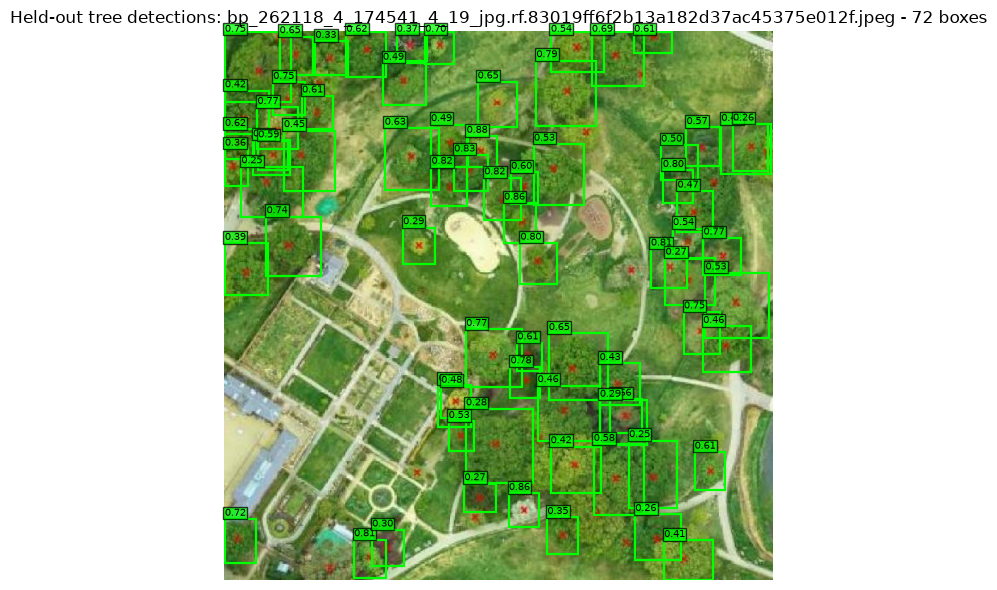

Predicted trees at confidence ≥ 0.25: 72
Ground-truth trees in this image: 86


In [16]:
tree_test_path = sorted((TREE_SPLITS["test"] / "images").glob("*"))[0]
tree_test_rgb = np.asarray(Image.open(tree_test_path).convert("RGB"))
tree_prediction = tree_detector.predict(
    source=str(tree_test_path), imgsz=640, conf=0.25, device=TREE_DEVICE,
    max_det=1000, verbose=False,
)[0]
tree_pred_boxes = tree_prediction.boxes.xyxy.cpu().numpy() if tree_prediction.boxes is not None else np.empty((0, 4))
tree_pred_scores = tree_prediction.boxes.conf.cpu().numpy() if tree_prediction.boxes is not None else np.empty(0)
show_detections(tree_test_rgb, tree_pred_boxes, tree_pred_scores,
                title=f"Held-out tree detections: {tree_test_path.name}")
print(f"Predicted trees at confidence ≥ 0.25: {len(tree_pred_boxes)}")
print(f"Ground-truth trees in this image: {len((TREE_SPLITS['test'] / 'labels' / f'{tree_test_path.stem}.txt').read_text().splitlines())}")


## Limitations and a practical workflow

### What this baseline does and does not establish

- The HSV/contour output is a **candidate generator**, not a trained or validated detector.
- Proposal counts depend on colour thresholds, morphology, and contour-size cutoffs; counts are not accuracy.
- Filename interpolation produces approximate geographic polygons only if the encoded corners, image orientation, and CRS assumption are correct.
- Geographic merging is useful for overlapping images, but cannot resolve an incorrect footprint or a pool missed in every tile.
- GPU use matters for neural training/inference; the classical OpenCV pipeline is CPU-friendly.

### Recommended next steps

1. Verify the tile coordinate convention against a trusted map or source metadata.
2. Manually box pools in a geographically representative subset, including difficult negatives; review annotations independently.
3. Make train/validation/test splits by non-overlapping sites and report the number of independent sites.
4. Compare the HSV baseline with a pretrained Faster R-CNN or RetinaNet using identical held-out sites and confidence/IoU conventions.
5. Report per-site precision, recall, AP@0.5 and mAP@0.5:0.95, plus uncertainty; inspect false positives and missed pools.
6. If only pool counts are needed, merge overlapping geospatial detections and validate counts per site before scaling.
7. For tree counting, inspect the held-out test predictions and verify that the chip split separates geographic areas before applying the model elsewhere.

The pool baseline has no independent reference boxes, so it cannot support accuracy claims. The tree model does have held-out annotations and reports test-set metrics, but only nine small chips are in the test split and the supplied split is not demonstrated to be geographically independent; treat its scores as a dataset demonstration, not evidence of transfer to new regions.
